# ClimaCity Paris -- 05. MLlib : prédiction et clustering (Jour 3 matin)

Ce carnet répond à la question du projet : **peut-on anticiper le taux d'occupation d'une station
pour l'heure suivante ?**

1. jeu de features horaire : calendrier, météo, taux d'occupation à `t-1` et `t-4`, avec des
   décalages **vérifiés en temps** ;
2. découpage **temporel** entraînement / test, et une référence naïve (la persistance) ;
3. Pipeline `VectorAssembler` -> `StandardScaler` -> `GBTRegressor`, hyperparamètres choisis par
   `CrossValidator` à 3 plis, chaque essai suivi dans **MLflow** ;
4. modèle **champion** : enregistré dans MLflow, sauvegardé, rechargé et appliqué à un nouveau lot ;
5. bonus : la qualité de l'air (NO2, PM2.5) améliore-t-elle la prédiction ? Et un `FMRegressor` ;
6. **K-Means** sur les profils horaires des stations (k de 3 à 8, coude et silhouette), avec la
   seconde mesure de la contrainte n°6 (calcul itératif avec et sans cache), puis une carte Folium.

Le carnet lit la table Delta `disponibilite` (carnet 03) et les tables `meteo_horaire` et
`air_horaire` (carnet 02).

## 1. Session et suivi MLflow

Le serveur MLflow tourne dans son propre conteneur. Deux expériences : une pour la prédiction, une
pour le clustering. Les modèles transitent par HTTP (`--serve-artifacts`).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..", "scripts").resolve()))
from config import *          # chemins, SEED, SHUFFLE_PARTITIONS, creer_session()

import json
import shutil
import time
import warnings

import folium
import matplotlib.pyplot as plt
import mlflow
import mlflow.spark
import pandas as pd
from mlflow.tracking import MlflowClient
from pyspark import StorageLevel
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator, RegressionEvaluator
from pyspark.ml.feature import StandardScaler, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.regression import FMRegressor, GBTRegressor
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.sql import functions as F
from pyspark.sql.window import Window

warnings.filterwarnings("ignore", module="mlflow")
# Le Spark UI ne garde par défaut que les 1 000 derniers jobs et stages : la validation croisée et les
# boucles K-Means en produisent davantage, on relève la limite pour pouvoir les relire.
spark = creer_session("ClimaCity-05-mllib-prediction",
                      spark__ui__retainedJobs="10000", spark__ui__retainedStages="10000")
sc = spark.sparkContext

mlflow.set_tracking_uri(MLFLOW_URI)
EXPERIENCE_PREDICTION = "ClimaCity - prédiction"
EXPERIENCE_CLUSTERING = "ClimaCity - profils de stations"
MODELE_ENREGISTRE = "climacity_gbt_taux_occupation"
client = MlflowClient()

shutil.rmtree(MODELES, ignore_errors=True)
MODELES.mkdir(parents=True)
print("Spark", spark.version, "| MLflow", mlflow.__version__, "->", MLFLOW_URI)

Spark 3.5.3 | MLflow 2.17.2 -> http://mlflow:5000


## 2. Le jeu de features

### Une série horaire par station

Les relevés arrivent tous les 15 à 50 minutes, à des instants qui varient d'un passage à l'autre. Le
modèle travaille à l'**heure** : on moyenne le taux d'occupation des relevés de chaque heure (UTC), par
station. On obtient une série horaire par station, avec des trous là où le collecteur n'est pas passé.

In [2]:
sc.setJobDescription("série horaire par station")
horaire = (spark.read.format("delta").load(str(DELTA_DISPONIBILITE))
           .groupBy("station_id", F.date_trunc("hour", "horodatage").alias("heure"))
           .agg(F.avg("taux_occupation").alias("taux_occupation"), F.count("*").alias("releves")))
horaire.persist(StorageLevel.MEMORY_AND_DISK)
n_horaire = horaire.count()
sc.setJobDescription(None)
n_heures = horaire.select("heure").distinct().count()
print(f"{n_horaire:,} heures-stations | {n_heures} heures distinctes".replace(",", " "))
horaire.groupBy("releves").count().orderBy("releves").show()

4 218 166 heures-stations | 3080 heures distinctes
+-------+-------+
|releves|  count|
+-------+-------+
|      1| 876051|
|      2|1040101|
|      3|1416943|
|      4| 870032|
|      5|  12301|
|      6|   1365|
|      9|   1373|
+-------+-------+



### Des décalages vérifiés en temps

La ligne cible est l'heure `t` : on prédit `taux_occupation(t)` à partir de ce qu'on sait à `t-1`. Les
features retardées sont le taux à **`t-1`** et à **`t-4`**.

Un `LAG(taux, 4)` naïf prendrait la **4e ligne précédente**, qui n'est à `t-4` que si aucune heure ne
manque. On utilise plutôt une fenêtre **en temps** : `rangeBetween(-4 h, -4 h)` sur l'horodatage en
secondes ne retient que la ligne située exactement 4 heures avant, ou rien. On compte les lignes où le
`LAG` naïf se serait trompé.

In [3]:
par_station = Window.partitionBy("station_id").orderBy(F.col("heure").cast("long"))


def taux_decale(heures: int):
    """Taux d'occupation de la même station exactement ``heures`` heures plus tôt.

    Args:
        heures: Décalage en heures (1 pour ``t-1``, 4 pour ``t-4``).

    Returns:
        Une colonne Spark : le taux de l'heure ``t - heures`` si elle existe, sinon null.

    Example:
        >>> horaire.withColumn("taux_t1", taux_decale(1))   # doctest: +SKIP
    """
    secondes = 3600 * heures
    return F.max("taux_occupation").over(par_station.rangeBetween(-secondes, -secondes))


lag_naif = F.lag("heure", 4).over(Window.partitionBy("station_id").orderBy("heure"))
controle = (horaire.withColumn("taux_t4", taux_decale(4))
            .withColumn("lag4_juste", lag_naif == F.col("heure") - F.expr("INTERVAL 4 HOURS")))
controle.agg(F.count("*").alias("lignes"),
             F.sum(F.expr("int(lag4_juste = false)")).alias("lag4_naif_faux"),
             F.sum(F.expr("int(lag4_juste = false AND taux_t4 IS NULL)")).alias("dont_t4_absent")).show()

+-------+--------------+--------------+
| lignes|lag4_naif_faux|dont_t4_absent|
+-------+--------------+--------------+
|4218166|        240304|         70369|
+-------+--------------+--------------+



Le `LAG` naïf se trompe sur **240 304 lignes** (5,7 % du jeu), là où il manque au moins une heure entre `t-4` et `t` :

- sur 169 935 d'entre elles, la vraie valeur de `t-4` existe, mais le `LAG` prendrait une heure plus ancienne ;
- sur 70 369, il n'y a **aucun** relevé à `t-4` : le `LAG` fabriquerait une valeur, là où la fenêtre en temps renvoie null et écarte la ligne.

Les erreurs se concentrent sur les trous de collecte vus au carnet 01 (janvier, et la panne du 4 au 8 février). Avec la fenêtre `rangeBetween`, `taux_t4` vaut toujours le taux de l'heure exacte `t-4`.

### Calendrier, météo et qualité de l'air

- **Calendrier** à l'heure de Paris (choix du carnet 02) : heure de la journée, jour de la semaine
  (1 = lundi), indicateur week-end.
- **Météo** de l'heure cible `t` : température et indicateur de pluie. En production, ce serait la
  **prévision** pour l'heure suivante ; on suppose ici une prévision parfaite.
- **Qualité de l'air** (bonus) : NO2 et PM2.5 de l'heure `t-1`, la dernière mesure connue au moment de
  prédire.

Les lignes sans `t-1` ou sans `t-4` sont écartées. Le jeu est persisté : il sert à toutes les sections.

In [4]:
meteo = (spark.read.parquet(str(METEO_PARQUET))
         .select(F.col("horodatage").alias("heure"), "temperature_c",
                 F.col("est_pluie").cast("double").alias("pluie")))
air = (spark.read.parquet(str(AIR_PARQUET))
       .select((F.col("horodatage") + F.expr("INTERVAL 1 HOUR")).alias("heure"),    # mesure de t-1
               F.col("no2_ugm3").alias("no2_t1"), F.col("pm25_ugm3").alias("pm25_t1")))
paris = F.from_utc_timestamp("heure", "Europe/Paris")

sc.setJobDescription("jeu de features")
jeu = (horaire
       .withColumn("taux_t1", taux_decale(1))
       .withColumn("taux_t4", taux_decale(4))
       .dropna(subset=["taux_t1", "taux_t4"])
       .join(F.broadcast(meteo), "heure")
       .join(F.broadcast(air), "heure", "left")
       .withColumn("heure_jour", F.hour(paris))
       .withColumn("jour_semaine", (F.dayofweek(paris) + 5) % 7 + 1)        # 1 = lundi ... 7 = dimanche
       .withColumn("est_weekend", (F.col("jour_semaine") >= 6).cast("double"))
       .select("station_id", "heure", "heure_jour", "jour_semaine", "est_weekend", "pluie",
               "temperature_c", "taux_t1", "taux_t4", "no2_t1", "pm25_t1", "taux_occupation"))
jeu.persist(StorageLevel.MEMORY_AND_DISK)
n_jeu = jeu.count()
sc.setJobDescription(None)
horaire.unpersist()

FEATURES = ["heure_jour", "jour_semaine", "est_weekend", "pluie", "temperature_c", "taux_t1", "taux_t4"]
FEATURES_AIR = FEATURES + ["no2_t1", "pm25_t1"]
print(f"{n_jeu:,} lignes | air manquant : {jeu.filter('no2_t1 IS NULL OR pm25_t1 IS NULL').count()}"
      .replace(",", " "))
jeu.show(3)

4 083 342 lignes | air manquant : 0
+----------+-------------------+----------+------------+-----------+-----+-------------+-------------------+------------------+-----------------+------------------+-------------------+
|station_id|              heure|heure_jour|jour_semaine|est_weekend|pluie|temperature_c|            taux_t1|           taux_t4|           no2_t1|           pm25_t1|    taux_occupation|
+----------+-------------------+----------+------------+-----------+-----+-------------+-------------------+------------------+-----------------+------------------+-------------------+
|      1003|2020-11-26 16:00:00|        17|           4|        0.0|  0.0|          7.8|0.36627906976744184|0.3953488372093023|64.94193548387096|29.685714285714287| 0.4651162790697674|
|      1003|2020-11-26 17:00:00|        18|           4|        0.0|  0.0|          5.5| 0.4651162790697674|0.3895348837209302|73.00967741935483| 31.94285714285714| 0.4127906976744186|
|      1003|2020-11-26 18:00:00|       

## 3. Découpage temporel et référence naïve

**ADAPTATION.** L'énoncé prévoit d'entraîner sur 2022 et d'évaluer sur 2023 ; l'historique public ne
couvre que l'hiver 2020-2021 (voir le README). On garde l'esprit : un découpage **dans le temps**, jamais
aléatoire, pour que le test soit réellement « dans le futur ». Les **85 % premières heures** servent à
l'entraînement, les 15 % dernières au test. Une **marge d'une heure** est retirée à la coupure : la
cible de la dernière heure d'entraînement serait sinon la feature `t-1` de la première heure de test.

La **persistance** (« l'heure prochaine ressemblera à celle-ci » : on prédit `taux_t1`) est la référence
à battre : un modèle qui ne fait pas mieux n'apporte rien.

In [5]:
heures = [r.heure for r in jeu.select("heure").distinct().orderBy("heure").collect()]   # ~3 000 valeurs
COUPURE = heures[int(len(heures) * 0.85)]
DEBUT = heures[0]
entrainement = jeu.filter(F.col("heure") < F.lit(COUPURE) - F.expr("INTERVAL 1 HOUR"))
test = jeu.filter(F.col("heure") >= F.lit(COUPURE))
n_entrainement, n_test = entrainement.count(), test.count()
print(f"Entraînement : {DEBUT:%d/%m/%Y} -> {COUPURE:%d/%m/%Y %H:%M} UTC | {n_entrainement:,} lignes".replace(",", " "))
print(f"Test         : {COUPURE:%d/%m/%Y %H:%M} -> {heures[-1]:%d/%m/%Y} | {n_test:,} lignes ".replace(",", " ")
      + f"({n_test / (n_entrainement + n_test):.1%})")


def evaluer(predictions) -> dict:
    """Calcule les métriques de régression d'un DataFrame de prédictions, en un seul passage.

    Args:
        predictions: DataFrame avec ``taux_occupation`` (vérité), ``prediction`` et ``taux_t1``.

    Returns:
        ``rmse``, ``mae``, ``r2`` (sur le taux) et ``r2_variation`` : part de la variance de
        la variation horaire (``taux - taux_t1``) expliquée. La persistance a un ``r2_variation``
        proche de 0, puisqu'elle prédit une variation nulle.

    Example:
        >>> evaluer(test.withColumn("prediction", F.col("taux_t1")))["rmse"]   # doctest: +SKIP
        0.080
    """
    erreur = F.col("prediction") - F.col("taux_occupation")
    variation = F.col("taux_occupation") - F.col("taux_t1")
    r = predictions.agg(
        F.sqrt(F.avg(erreur ** 2)).alias("rmse"), F.avg(F.abs(erreur)).alias("mae"),
        F.sum(erreur ** 2).alias("sse"), F.var_pop("taux_occupation").alias("var_taux"),
        F.var_pop(variation).alias("var_variation"), F.count("*").alias("n")).first()
    return {"rmse": r.rmse, "mae": r.mae,
            "r2": 1 - r.sse / (r.var_taux * r.n),
            "r2_variation": 1 - r.sse / (r.var_variation * r.n)}


mlflow.set_experiment(EXPERIENCE_PREDICTION)
resultats = {}
with mlflow.start_run(run_name="persistance"):
    resultats["persistance"] = evaluer(test.withColumn("prediction", F.col("taux_t1")))
    mlflow.log_param("modele", "persistance (taux_t1)")
    mlflow.log_metrics({f"test_{k}": v for k, v in resultats["persistance"].items()})
print("Persistance :", {k: round(v, 4) for k, v in resultats["persistance"].items()})

Entraînement : 26/11/2020 -> 21/03/2021 18:00 UTC | 3 469 961 lignes
Test         : 21/03/2021 18:00 -> 09/04/2021 | 612 013 lignes (15.0%)


2026/10/29 13:53:45 INFO mlflow.tracking._tracking_service.client: 🏃 View run persistance at: http://mlflow:5000/#/experiments/1/runs/9ad821e8d90c43e3a20a3943d6caecae.


2026/10/29 13:53:45 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/1.


Persistance : {'rmse': 0.08, 'mae': 0.0465, 'r2': 0.8921, 'r2_variation': -0.0}


## 4. Pipeline et validation croisée

Le Pipeline enchaîne trois étapes : `VectorAssembler` (les colonnes en un vecteur), `StandardScaler`
(centrage-réduction ; inutile pour des arbres, mais il fait partie de la chaîne demandée et servira au
`FMRegressor`), puis `GBTRegressor`. Le Pipeline entier est l'objet qu'on entraîne, sauvegarde et
recharge : la préparation des features voyage avec le modèle.

Les hyperparamètres : `maxDepth` (profondeur des arbres) et `maxIter`, le nombre d'arbres du boosting.
C'est l'équivalent pour GBT du `numTrees` cité par l'énoncé, qui est un paramètre des forêts aléatoires.

**Plis temporels.** Un `CrossValidator` répartit les lignes au hasard entre les plis. Les heures voisines
d'une même station se ressemblant beaucoup, il mesurerait surtout la capacité à interpoler. On fournit
donc les plis (`foldCol`) : trois **périodes successives** de la période d'entraînement.

La validation croisée porte sur un **échantillon de 25 %** de l'entraînement (6 combinaisons × 3 plis
= 18 entraînements). Le champion est ensuite réentraîné sur tout l'entraînement. Chaque combinaison est
un run MLflow « enfant » du run de validation croisée.

In [6]:
duree_entrainement = (COUPURE - DEBUT).total_seconds()
echantillon = (entrainement.sample(fraction=0.25, seed=SEED)
               .withColumn("pli", F.least(F.lit(2), F.floor(
                   3 * (F.col("heure").cast("long") - F.lit(int(DEBUT.timestamp())))
                   / F.lit(duree_entrainement)).cast("int"))))
echantillon.persist(StorageLevel.MEMORY_AND_DISK)
echantillon.groupBy("pli").agg(F.count("*").alias("lignes"), F.min("heure").alias("debut"),
                               F.max("heure").alias("fin")).orderBy("pli").show(truncate=False)


def pipeline_gbt(features: list[str], **parametres) -> Pipeline:
    """Construit le Pipeline VectorAssembler -> StandardScaler -> GBTRegressor.

    Args:
        features: Colonnes d'entrée, dans l'ordre du vecteur.
        **parametres: Hyperparamètres du ``GBTRegressor`` (``maxDepth``, ``maxIter``...).

    Returns:
        Le Pipeline non entraîné ; la cible est ``taux_occupation``.

    Example:
        >>> pipeline_gbt(FEATURES, maxDepth=5).getStages()[-1].getMaxDepth()
        5
    """
    return Pipeline(stages=[
        VectorAssembler(inputCols=features, outputCol="features_brutes"),
        StandardScaler(inputCol="features_brutes", outputCol="features", withMean=True, withStd=True),
        GBTRegressor(featuresCol="features", labelCol="taux_occupation", seed=SEED, **parametres),
    ])


pipeline = pipeline_gbt(FEATURES)
gbt = pipeline.getStages()[-1]
grille = (ParamGridBuilder()
          .addGrid(gbt.maxDepth, [3, 5, 7])
          .addGrid(gbt.maxIter, [20, 50])
          .build())
validation = CrossValidator(estimator=pipeline, estimatorParamMaps=grille,
                            evaluator=RegressionEvaluator(labelCol="taux_occupation", metricName="rmse"),
                            numFolds=3, foldCol="pli", parallelism=2, seed=SEED)

with mlflow.start_run(run_name="validation_croisee") as run_cv:
    t0 = time.perf_counter()
    modele_cv = validation.fit(echantillon)
    duree_cv = time.perf_counter() - t0
    mlflow.log_params({"plis": 3, "decoupage_plis": "temporel", "echantillon": 0.25,
                       "lignes_echantillon": echantillon.count()})
    mlflow.log_metric("duree_s", duree_cv)
    essais = []
    for parametres, moyenne, ecart in zip(grille, modele_cv.avgMetrics, modele_cv.stdMetrics):
        valeurs = {p.name: v for p, v in parametres.items()}
        essais.append({**valeurs, "rmse_cv": moyenne, "ecart_type": ecart})
        with mlflow.start_run(run_name=f"gbt_profondeur{valeurs['maxDepth']}_arbres{valeurs['maxIter']}",
                              nested=True):
            mlflow.log_params(valeurs)
            mlflow.log_metrics({"rmse_cv": moyenne, "rmse_cv_ecart_type": ecart})

essais = pd.DataFrame(essais).sort_values("rmse_cv")
meilleur = modele_cv.bestModel.stages[-1]
MEILLEURS_PARAMETRES = {"maxDepth": meilleur.getMaxDepth(), "maxIter": meilleur.getMaxIter()}
print(f"Validation croisée en {duree_cv:.0f} s | meilleurs paramètres : {MEILLEURS_PARAMETRES}")
essais.round(5)

+---+------+-------------------+-------------------+
|pli|lignes|debut              |fin                |
+---+------+-------------------+-------------------+
|0  |311026|2020-11-26 16:00:00|2021-01-04 00:00:00|
|1  |246114|2021-01-04 03:00:00|2021-02-11 09:00:00|
|2  |311481|2021-02-11 10:00:00|2021-03-21 16:00:00|
+---+------+-------------------+-------------------+



2026/10/29 13:56:19 INFO mlflow.tracking._tracking_service.client: 🏃 View run gbt_profondeur3_arbres20 at: http://mlflow:5000/#/experiments/1/runs/eaec1339a7164c119c3660b7f7ab6425.


2026/10/29 13:56:19 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/1.


2026/10/29 13:56:19 INFO mlflow.tracking._tracking_service.client: 🏃 View run gbt_profondeur3_arbres50 at: http://mlflow:5000/#/experiments/1/runs/59b706743a2e4a0d807b97dd7c53581c.


2026/10/29 13:56:19 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/1.


...

2026/10/29 13:56:20 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/1.


2026/10/29 13:56:20 INFO mlflow.tracking._tracking_service.client: 🏃 View run validation_croisee at: http://mlflow:5000/#/experiments/1/runs/a4c7b4c645ea447ea5a3d41e51f9c8d9.


2026/10/29 13:56:20 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/1.


Validation croisée en 153 s | meilleurs paramètres : {'maxDepth': 7, 'maxIter': 50}


,maxDepth,maxIter,rmse_cv,ecart_type
5,7,50,0.07389,0.00344
3,5,50,0.07395,0.00363
4,7,20,0.07406,0.00358
2,5,20,0.07434,0.00374
1,3,50,0.07559,0.00401
0,3,20,0.07823,0.00388


Sur les six combinaisons, les arbres plus profonds et plus nombreux gagnent : **profondeur 7 et 50 arbres** (RMSE 0,0739 en validation croisée). L'écart avec la profondeur 5 (0,0740) est toutefois bien plus petit que l'écart-type entre plis (0,0034) : au-delà de la profondeur 5, le gain est négligeable. Les arbres de profondeur 3 sont nettement moins bons, surtout avec 20 arbres (0,0782).

L'écart-type entre plis vient surtout de la période : le premier pli (fin novembre - début janvier) et le dernier (mi-février - mars) n'ont pas la même météo ni les mêmes contraintes sanitaires. Avec des plis tirés au hasard, cette variabilité serait masquée. La validation croisée a pris environ 2 min 30 (18 entraînements, deux à la fois).

## 5. Le modèle champion

On réentraîne le Pipeline avec les meilleurs paramètres sur **tout** l'entraînement, puis on l'évalue sur
le test. Le run MLflow `gbt_champion` garde les paramètres, les métriques, l'importance des features, un
graphique, et le modèle lui-même. Le modèle est inscrit au **registre** de MLflow, avec l'alias
`champion` : le reste du projet le désignera par cet alias, sans connaître le numéro de version.

In [7]:
with mlflow.start_run(run_name="gbt_champion") as run_champion:
    t0 = time.perf_counter()
    champion = pipeline_gbt(FEATURES, **MEILLEURS_PARAMETRES).fit(entrainement)
    duree_champion = time.perf_counter() - t0
    predictions_test = champion.transform(test).persist(StorageLevel.MEMORY_AND_DISK)
    resultats["gbt"] = evaluer(predictions_test)
    importances = dict(zip(FEATURES, champion.stages[-1].featureImportances.toArray().round(4).tolist()))

    mlflow.log_params({**MEILLEURS_PARAMETRES, "features": ",".join(FEATURES),
                       "lignes_entrainement": n_entrainement, "coupure": str(COUPURE)})
    mlflow.log_metrics({**{f"test_{k}": v for k, v in resultats["gbt"].items()},
                        "duree_entrainement_s": duree_champion})
    mlflow.log_dict(importances, "importance_features.json")
    info = mlflow.spark.log_model(champion, artifact_path="modele", registered_model_name=MODELE_ENREGISTRE,
                                  pip_requirements=["pyspark==3.5.3"])
    version = max(int(v.version) for v in client.search_model_versions(f"name='{MODELE_ENREGISTRE}'"))
    client.set_registered_model_alias(MODELE_ENREGISTRE, "champion", str(version))

print(f"Entraînement sur {n_entrainement:,} lignes en {duree_champion:.0f} s".replace(",", " "))
print(pd.DataFrame(resultats).T.round(4))
print("Importance des features :", importances)
print(f"Registre MLflow : {MODELE_ENREGISTRE}, version {version}, alias « champion »")

2026/10/29 13:57:15 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


Registered model 'climacity_gbt_taux_occupation' already exists. Creating a new version of this model...
2026/10/29 13:57:15 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: climacity_gbt_taux_occupation, version 2


Created version '2' of model 'climacity_gbt_taux_occupation'.
2026/10/29 13:57:15 INFO mlflow.tracking._tracking_service.client: 🏃 View run gbt_champion at: http://mlflow:5000/#/experiments/1/runs/78011b19bcfc4e969224f17f77d0c104.


2026/10/29 13:57:15 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/1.


Entraînement sur 3 469 961 lignes en 53 s
               rmse     mae      r2  r2_variation
persistance  0.0800  0.0465  0.8921       -0.0000
gbt          0.0756  0.0471  0.9035        0.1057
Importance des features : {'heure_jour': 0.0198, 'jour_semaine': 0.0045, 'est_weekend': 0.0024, 'pluie': 0.0003, 'temperature_c': 0.0021, 'taux_t1': 0.9552, 'taux_t4': 0.0157}
Registre MLflow : climacity_gbt_taux_occupation, version 2, alias « champion »


L'erreur dépend-elle de l'heure ? On compare, heure par heure, la RMSE du modèle et celle de la
persistance sur le test (24 lignes ramenées dans Pandas). Le graphique est aussi rangé dans le run MLflow.

2026/10/29 13:57:15 INFO mlflow.tracking._tracking_service.client: 🏃 View run gbt_champion at: http://mlflow:5000/#/experiments/1/runs/78011b19bcfc4e969224f17f77d0c104.


2026/10/29 13:57:15 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/1.


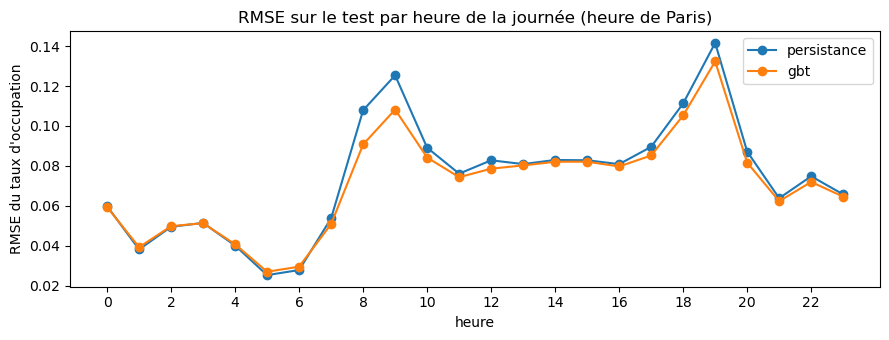

Gain de RMSE sur la persistance : 3 h +0 %, 8 h +16 %, 9 h +14 %, 13 h +1 %, 18 h +5 %, 19 h +7 %, 22 h +4 %


In [8]:
par_heure = (predictions_test.groupBy("heure_jour")
             .agg(F.sqrt(F.avg((F.col("prediction") - F.col("taux_occupation")) ** 2)).alias("gbt"),
                  F.sqrt(F.avg((F.col("taux_t1") - F.col("taux_occupation")) ** 2)).alias("persistance"))
             .orderBy("heure_jour").toPandas().set_index("heure_jour"))

fig, ax = plt.subplots(figsize=(9, 3.5))
par_heure[["persistance", "gbt"]].plot(ax=ax, marker="o")
ax.set_title("RMSE sur le test par heure de la journée (heure de Paris)")
ax.set_xlabel("heure")
ax.set_ylabel("RMSE du taux d'occupation")
ax.set_xticks(range(0, 24, 2))
plt.tight_layout()
with mlflow.start_run(run_id=run_champion.info.run_id):
    mlflow.log_figure(fig, "rmse_par_heure.png")
plt.show()
gain = (1 - par_heure["gbt"] / par_heure["persistance"]) * 100
print("Gain de RMSE sur la persistance : "
      + ", ".join(f"{h} h {g:+.0f} %" for h, g in gain.items() if h in (3, 8, 9, 13, 18, 19, 22)))

Le GBT bat la persistance : **RMSE 0,0756 contre 0,0800** (-5,4 %), **R² 0,904 contre 0,892**. Le R² élevé de la persistance montre surtout que le taux d'une heure ressemble beaucoup à celui de l'heure précédente. La mesure la plus parlante est le **R² sur la variation horaire** : le modèle explique **10,6 %** de la variation entre `t-1` et `t`, là où la persistance n'en explique rien.

- **Où le modèle gagne-t-il ?** Aux heures où les stations bougent : **-16 % d'erreur à 8 h, -14 % à 9 h**, -5 à -7 % à la pointe du soir. La nuit, rien ne bouge, et la persistance est déjà presque parfaite. Le modèle a appris le **sens** des pointes (les stations de bureaux se remplissent le matin) grâce à l'heure et au jour.
- **La MAE est légèrement moins bonne** (0,0471 contre 0,0465). Le GBT minimise l'erreur quadratique : il corrige bien les grosses variations des pointes, mais introduit de petites erreurs là où la persistance est exacte (station immobile).
- **Importance des features** : `taux_t1` porte 95,5 % des décisions des arbres, puis l'heure (2 %) et `taux_t4` (1,6 %). La météo pèse très peu, ce qui est cohérent avec la question 2 du carnet 03 : la pluie réduit les déplacements d'un quart, mais ne déplace le taux d'occupation que d'un point en moyenne.
- Le test (21 mars - 9 avril) inclut le début du **troisième confinement** (3 avril), une situation absente de l'entraînement.

Le modèle est inscrit au registre comme nouvelle version de `climacity_gbt_taux_occupation`, et l'alias `champion` est déplacé sur elle : rejouer le carnet crée une version de plus, sans casser les références à l'alias.

## 6. Sauvegarde, rechargement et application à un nouveau lot

Deux façons de retrouver le modèle :

- `save()` / `PipelineModel.load()` : le format natif de Spark, un dossier (métadonnées JSON et arbres
  en Parquet) ;
- le **registre MLflow** : `models:/<nom>@champion` désigne la version marquée champion, quelle qu'elle
  soit.

Le « nouveau lot » est la journée du **9 avril 2021**, celle que le `MERGE` du carnet 03 a ajoutée à la
table Delta. On vérifie que les deux modèles rechargés donnent **exactement** les prédictions du modèle
en mémoire.

In [9]:
chemin_champion = MODELES / "gbt_champion"
champion.write().overwrite().save(str(chemin_champion))
print("Sauvegardé :", sorted(p.name for p in chemin_champion.iterdir()),
      "| étapes :", sorted(p.name for p in (chemin_champion / "stages").iterdir()))

recharge = PipelineModel.load(str(chemin_champion))
depuis_mlflow = mlflow.spark.load_model(f"models:/{MODELE_ENREGISTRE}@champion")

nouveau_lot = jeu.filter(F.to_date("heure") == "2021-04-09")
comparaison = (champion.transform(nouveau_lot).select("station_id", "heure", "taux_occupation", "taux_t1", "prediction")
               .join(recharge.transform(nouveau_lot).select("station_id", "heure", F.col("prediction").alias("p_disque")),
                     ["station_id", "heure"])
               .join(depuis_mlflow.transform(nouveau_lot).select("station_id", "heure", F.col("prediction").alias("p_mlflow")),
                     ["station_id", "heure"]))
ecarts = comparaison.agg(F.count("*").alias("lignes"),
                         F.max(F.abs(F.col("prediction") - F.col("p_disque"))).alias("ecart_disque"),
                         F.max(F.abs(F.col("prediction") - F.col("p_mlflow"))).alias("ecart_mlflow")).first()
print(f"9 avril : {ecarts.lignes} prédictions | écart max disque : {ecarts.ecart_disque} | "
      f"écart max MLflow : {ecarts.ecart_mlflow}")
assert ecarts.ecart_disque == 0 and ecarts.ecart_mlflow == 0
print("Métriques sur le nouveau lot :", {k: round(v, 4) for k, v in evaluer(comparaison).items()})

Sauvegardé : ['metadata', 'stages'] | étapes : ['0_VectorAssembler_0d2989d67cfa', '1_StandardScaler_7dec55e58b74', '2_GBTRegressor_b7ecc3e4bbba']


2026/10/29 13:57:22 INFO mlflow.spark: 'models:/climacity_gbt_taux_occupation@champion' resolved as 'mlflow-artifacts:/1/78011b19bcfc4e969224f17f77d0c104/artifacts/modele'


2026/10/29 13:57:22 INFO mlflow.spark: URI 'models:/climacity_gbt_taux_occupation@champion/sparkml' does not point to the current DFS.


2026/10/29 13:57:22 INFO mlflow.spark: File 'models:/climacity_gbt_taux_occupation@champion/sparkml' not found on DFS. Will attempt to upload the file.


9 avril : 20490 prédictions | écart max disque : 0.0 | écart max MLflow : 0.0


Métriques sur le nouveau lot : {'rmse': 0.0663, 'mae': 0.0416, 'r2': 0.9202, 'r2_variation': 0.1123}


## 7. Bonus : qualité de l'air et `FMRegressor`

### La qualité de l'air aide-t-elle ?

On réentraîne le même Pipeline, avec les mêmes hyperparamètres, en ajoutant le NO2 et les PM2.5 de
l'heure précédente. Le NO2 suit le trafic routier : il pourrait porter une information sur l'activité de
la ville que le calendrier ne capte pas. Seule la liste des features change ; les deux runs MLflow se
comparent directement.

In [10]:
jeu_air_entrainement = entrainement.dropna(subset=["no2_t1", "pm25_t1"])
jeu_air_test = test.dropna(subset=["no2_t1", "pm25_t1"])
print(f"Lignes sans mesure d'air écartées : {n_entrainement - jeu_air_entrainement.count()} (entraînement), "
      f"{n_test - jeu_air_test.count()} (test)")

with mlflow.start_run(run_name="gbt_qualite_air"):
    t0 = time.perf_counter()
    modele_air = pipeline_gbt(FEATURES_AIR, **MEILLEURS_PARAMETRES).fit(jeu_air_entrainement)
    duree_air = time.perf_counter() - t0
    resultats["gbt_air"] = evaluer(modele_air.transform(jeu_air_test))
    resultats["gbt_meme_test"] = evaluer(champion.transform(jeu_air_test))      # même test, sans l'air
    importances_air = dict(zip(FEATURES_AIR, modele_air.stages[-1].featureImportances.toArray().round(4).tolist()))
    mlflow.log_params({**MEILLEURS_PARAMETRES, "features": ",".join(FEATURES_AIR)})
    mlflow.log_metrics({**{f"test_{k}": v for k, v in resultats["gbt_air"].items()},
                        "duree_entrainement_s": duree_air})
    mlflow.log_dict(importances_air, "importance_features.json")

print(pd.DataFrame({k: resultats[k] for k in ["gbt_meme_test", "gbt_air"]}).T.round(5))
print("Importance des features :", importances_air)

Lignes sans mesure d'air écartées : 0 (entraînement), 0 (test)


2026/10/29 13:58:21 INFO mlflow.tracking._tracking_service.client: 🏃 View run gbt_qualite_air at: http://mlflow:5000/#/experiments/1/runs/cc4bd0526b9a49f7ba65d31afb1e1f08.


2026/10/29 13:58:21 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/1.


                  rmse      mae       r2  r2_variation
gbt_meme_test  0.07565  0.04705  0.90355       0.10571
gbt_air        0.07572  0.04739  0.90335       0.10392
Importance des features : {'heure_jour': 0.0199, 'jour_semaine': 0.0038, 'est_weekend': 0.0025, 'pluie': 0.0001, 'temperature_c': 0.0014, 'taux_t1': 0.9532, 'taux_t4': 0.0152, 'no2_t1': 0.0022, 'pm25_t1': 0.0016}


### Un autre estimateur : `FMRegressor`

Les **machines de factorisation** (`FMRegressor`) modélisent une régression linéaire plus toutes les
interactions deux à deux entre features, chacune approchée par un produit de petits vecteurs. Contrairement
aux arbres, elles sont sensibles à l'échelle des features : le `StandardScaler` du Pipeline devient utile.
L'optimisation (AdamW, 100 itérations) étant plus lente, on l'entraîne sur l'échantillon de 25 %.

In [11]:
pipeline_fm = Pipeline(stages=[
    VectorAssembler(inputCols=FEATURES, outputCol="features_brutes"),
    StandardScaler(inputCol="features_brutes", outputCol="features", withMean=True, withStd=True),
    FMRegressor(featuresCol="features", labelCol="taux_occupation", factorSize=8, maxIter=100,
                stepSize=0.01, seed=SEED),
])
with mlflow.start_run(run_name="fm_regressor"):
    t0 = time.perf_counter()
    modele_fm = pipeline_fm.fit(echantillon)
    duree_fm = time.perf_counter() - t0
    resultats["fm"] = evaluer(modele_fm.transform(test))
    mlflow.log_params({"modele": "FMRegressor", "factorSize": 8, "maxIter": 100, "stepSize": 0.01,
                       "echantillon": 0.25, "features": ",".join(FEATURES)})
    mlflow.log_metrics({**{f"test_{k}": v for k, v in resultats["fm"].items()}, "duree_entrainement_s": duree_fm})
print(f"FMRegressor entraîné en {duree_fm:.0f} s :", {k: round(v, 4) for k, v in resultats["fm"].items()})

2026/10/29 13:58:48 INFO mlflow.tracking._tracking_service.client: 🏃 View run fm_regressor at: http://mlflow:5000/#/experiments/1/runs/cfac69b66a3d4f309d0ff90638639db4.


2026/10/29 13:58:48 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/1.


FMRegressor entraîné en 27 s : {'rmse': 0.0831, 'mae': 0.0549, 'r2': 0.8836, 'r2_variation': -0.079}


Les modèles côte à côte (les métriques sont aussi dans l'interface MLflow, où l'on peut comparer les runs) :

                       rmse      mae       r2  r2_variation
persistance         0.07999  0.04654  0.89214      -0.00000
FMRegressor         0.08309  0.05491  0.88363      -0.07896
GBT (champion)      0.07565  0.04705  0.90355       0.10571
GBT, test avec air  0.07565  0.04705  0.90355       0.10571
GBT + NO2 / PM2.5   0.07572  0.04739  0.90335       0.10392


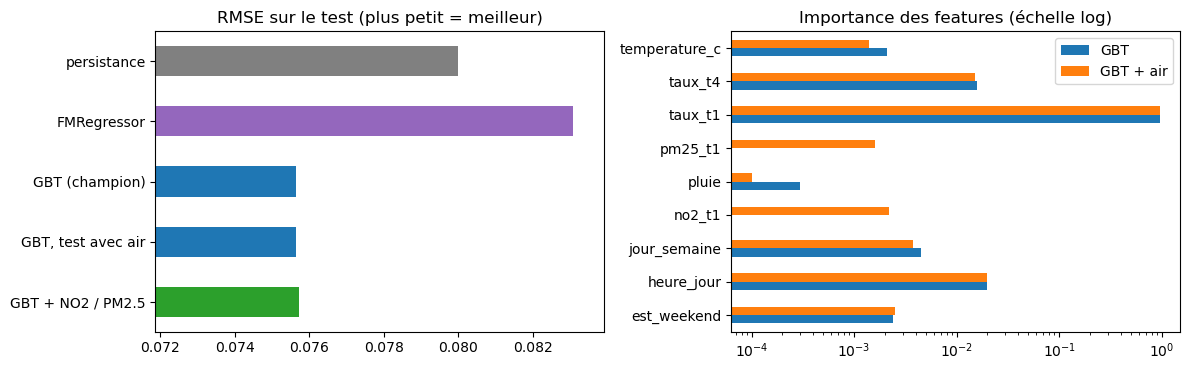

In [12]:
tableau = pd.DataFrame(resultats).T.loc[["persistance", "fm", "gbt", "gbt_meme_test", "gbt_air"]]
tableau.index = ["persistance", "FMRegressor", "GBT (champion)", "GBT, test avec air", "GBT + NO2 / PM2.5"]
print(tableau.round(5))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
tableau["rmse"].plot.barh(ax=axes[0], color=["grey", "tab:purple", "tab:blue", "tab:blue", "tab:green"])
axes[0].set_xlim(tableau["rmse"].min() * 0.95, tableau["rmse"].max() * 1.01)
axes[0].set_title("RMSE sur le test (plus petit = meilleur)")
axes[0].invert_yaxis()
pd.DataFrame({"GBT": pd.Series(importances), "GBT + air": pd.Series(importances_air)}).plot.barh(ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title("Importance des features (échelle log)")
plt.tight_layout()
plt.show()

**Qualité de l'air.** Ajouter le NO2 et les PM2.5 de l'heure précédente **n'améliore pas** la prédiction : RMSE 0,07572 contre 0,07565 sur exactement le même test, soit un très léger recul. Les deux variables pèsent 0,2 % chacune dans les arbres. L'explication est double : le NO2 suit le **cycle du trafic**, que l'heure et le jour décrivent déjà, et l'information qui compte vraiment (le taux de la station à `t-1`) est locale, alors que la qualité de l'air est une moyenne régionale. Les PM2.5 dépendent surtout de la météo et des épisodes de pollution, sans lien direct avec l'usage des vélos dans l'heure. Le bonus répond donc par la négative, chiffres à l'appui.

**`FMRegressor`.** Il fait **moins bien que la persistance** (RMSE 0,0831, R² sur la variation de -7,9 %). Le modèle est linéaire, avec des interactions deux à deux : il traite l'heure comme un nombre (23 h « loin » de 0 h) et ne peut pas représenter un pic à 8 h puis un creux à 13 h. Il faudrait encoder l'heure en catégories (`OneHotEncoder`), ce que les arbres du GBT n'exigent pas. C'est aussi un rappel utile : un modèle plus complexe n'est utile que s'il bat la référence naïve.

Le **champion reste le GBT sans qualité de l'air**.

## 8. K-Means : des profils de stations

Chaque station est décrite par son **profil moyen d'occupation par heure de la journée** (heure de
Paris), calculé sur les **jours ouvrés** : un vecteur de 24 valeurs entre 0 et 1. Le profil mêle le
niveau (station plutôt pleine ou plutôt vide) et la forme (moment où elle se remplit). On ne le
standardise pas : toutes les composantes sont déjà dans la même unité.

Le profil se calcule depuis les 10,7 millions de relevés de la table Delta : agrégation, puis `pivot`
sur les 24 heures, avec les valeurs listées pour éviter un passage de plus sur les données. On libère
d'abord les tables persistées de la partie prédiction, devenues inutiles.

Les stations auxquelles il manque une heure sont écartées par `VectorAssembler(handleInvalid="skip")`
plutôt que par un `dropna()` sur les 24 colonnes. Dans une première version, ce `dropna()` suivi de la
jointure avec les noms et coordonnées faisait **saturer la mémoire du driver** avant même le premier
calcul : l'optimiseur Catalyst déduit de chaque filtre `IS NOT NULL` des contraintes qu'il propage à
travers la jointure, et leurs combinaisons sur 24 colonnes font exploser la taille du plan.

Enfin, les profils sont **triés et réunis en une seule partition**. L'initialisation de K-Means
(k-means||) tire des points au hasard partition par partition : avec une graine fixe, le résultat ne
dépend plus que de l'ordre et du découpage des lignes. Après un `groupBy`, cet ordre varie d'une
exécution à l'autre (les blocs du shuffle arrivent dans un ordre quelconque). Une première version de la
mesure ci-dessous obtenait ainsi des inerties différentes de 2 à 3 % entre deux calculs identiques. Une
partition suffit largement pour 1 381 vecteurs ; l'agrégation des 10,7 millions de relevés, en amont,
reste parallèle.

In [13]:
# La partie prédiction est finie : on libère ses DataFrames persistés (plus de 1 Go de mémoire du driver).
for df in [jeu, echantillon, predictions_test]:
    df.unpersist(blocking=True)

HEURES = list(range(24))
releves_ouvres = (spark.read.format("delta").load(str(DELTA_DISPONIBILITE))
                  .withColumn("paris", F.from_utc_timestamp("horodatage", "Europe/Paris"))
                  .filter(F.dayofweek("paris").between(2, 6)))
profils = (releves_ouvres
           .groupBy("station_id", F.hour("paris").alias("h"))
           .agg(F.avg("taux_occupation").alias("taux"))
           .groupBy("station_id").pivot("h", HEURES).agg(F.first("taux")))
profils = (VectorAssembler(inputCols=[str(h) for h in HEURES], outputCol="features", handleInvalid="skip")
           .transform(profils)
           .select("station_id", "features")
           .join(releves_ouvres.groupBy("station_id").agg(
                     F.first("nom_station").alias("nom_station"), F.first("arrondissement").alias("arrondissement"),
                     F.avg("latitude").alias("latitude"), F.avg("longitude").alias("longitude")), "station_id")
           .orderBy("station_id").coalesce(1))    # ordre et partitionnement fixes : voir ci-dessous
print(profils.count(), "stations avec un profil complet")

1381 stations avec un profil complet


### Contrainte n°6 : un calcul itératif, avec et sans cache

Choisir `k` demande d'entraîner six modèles (k de 3 à 8) et de calculer la silhouette de chacun. K-Means
est **itératif** : chaque itération repasse sur toutes les stations. Sans cache, chaque action relance
tout le plan en amont, ici la lecture et l'agrégation des 10,7 millions de relevés. K-Means persiste
lui-même ses vecteurs le temps d'un entraînement, mais pas d'un modèle à l'autre, ni pour l'évaluation.

On exécute la même boucle deux fois : (A) profils non persistés, (B) profils persistés en mémoire. Le
Spark UI (lu par son API REST) donne pour chaque boucle le nombre de jobs et de stages et le volume lu.

In [14]:
def boucle_kmeans(donnees, description: str) -> tuple[list[dict], float]:
    """Entraîne K-Means pour k de 3 à 8 et calcule inertie et silhouette de chaque modèle.

    Args:
        donnees: DataFrame avec une colonne ``features`` (persisté ou non).
        description: Description des jobs Spark, pour les retrouver dans le Spark UI.

    Returns:
        La liste des résultats par k (``k``, ``inertie``, ``silhouette``, ``iterations``) et la durée
        totale de la boucle, en secondes.

    Example:
        >>> resultats_k, duree = boucle_kmeans(profils, "kmeans test")   # doctest: +SKIP
    """
    evaluateur = ClusteringEvaluator(featuresCol="features", predictionCol="cluster",
                                     metricName="silhouette", distanceMeasure="squaredEuclidean")
    sc.setJobDescription(description)
    t0 = time.perf_counter()
    lignes = []
    for k in range(3, 9):
        modele = KMeans(k=k, featuresCol="features", predictionCol="cluster", seed=SEED, maxIter=50).fit(donnees)
        lignes.append({"k": k, "inertie": modele.summary.trainingCost,
                       "silhouette": evaluateur.evaluate(modele.transform(donnees)),
                       "iterations": modele.summary.numIter})
    duree = time.perf_counter() - t0
    sc.setJobDescription(None)
    return lignes, duree


def resume_spark_ui(description: str) -> dict:
    """Résume les jobs Spark d'une boucle à partir de l'API REST du Spark UI.

    Args:
        description: Description passée à ``sc.setJobDescription`` pendant la boucle.

    Returns:
        Le nombre de jobs et de stages exécutés, le volume lu (Mo) et le temps de calcul cumulé
        des tâches (s).

    Example:
        >>> resume_spark_ui("kmeans sans cache")   # doctest: +SKIP
        {'jobs': 120, 'stages': 200, 'entree_mo': 900.0, 'calcul_s': 150.0}
    """
    stages = stages_spark_ui(spark, description, tous_les_jobs=True)
    executes = [s for s in stages if s["statut"] == "COMPLETE"]
    return {"jobs": len({s["job"] for s in stages}), "stages": len(executes),
            "entree_mo": round(sum(s["entree_mo"] for s in executes), 1),
            "calcul_s": round(sum(s["calcul_s"] for s in executes), 1)}


resultats_k, duree_sans_cache = boucle_kmeans(profils, "kmeans sans cache")
ui_sans_cache = resume_spark_ui("kmeans sans cache")

profils.persist(StorageLevel.MEMORY_ONLY)
t0 = time.perf_counter()
profils.count()                                             # remplissage du cache
duree_remplissage = time.perf_counter() - t0
resultats_k_cache, duree_avec_cache = boucle_kmeans(profils, "kmeans avec cache")
ui_avec_cache = resume_spark_ui("kmeans avec cache")

# Mêmes modèles dans les deux boucles, à l'arrondi des sommes flottantes près : sans cache, les moyennes
# sont recalculées à chaque modèle et l'ordre des additions peut changer.
print(pd.DataFrame({"inertie_sans_cache": [r["inertie"] for r in resultats_k],
                    "inertie_avec_cache": [r["inertie"] for r in resultats_k_cache]}, index=range(3, 9)))
ecart_inertie = max(abs(a["inertie"] - b["inertie"]) / b["inertie"] for a, b in zip(resultats_k, resultats_k_cache))
print(f"Écart relatif maximal d'inertie entre les deux boucles : {ecart_inertie:.1e}")
assert ecart_inertie < 1e-6
mesure_cache = pd.DataFrame([{"boucle": "A, sans cache", "duree_s": duree_sans_cache, **ui_sans_cache},
                             {"boucle": "B, avec cache", "duree_s": duree_avec_cache, **ui_avec_cache}]
                            ).set_index("boucle")
print(f"Remplissage du cache : {duree_remplissage:.1f} s")
mesure_cache.round(1)

   inertie_sans_cache  inertie_avec_cache
3          418.002478          418.002478
4          299.612830          299.612830
5          260.366366          260.366366
6          223.195613          223.195613
7          203.306343          203.306343
8          176.547467          176.547467
Écart relatif maximal d'inertie entre les deux boucles : 0.0e+00
Remplissage du cache : 1.5 s


,duree_s,jobs,stages,entree_mo,calcul_s
boucle,,,,,
"A, sans cache",41.3,335,442,1536.5,225.0
"B, avec cache",2.5,161,268,56.2,0.3


La seconde mesure de la contrainte n°6 est sans appel : la boucle passe de **41 s sans cache à 2,5 s avec cache** (plus 1,5 s pour remplir le cache), soit **16 fois plus vite**, pour des modèles identiques (même inertie à chaque `k`).

Le Spark UI explique l'écart :

- **sans cache**, les 335 jobs relisent au total **1,5 Go** depuis la table Delta, et le temps de calcul cumulé des tâches atteint **225 s**. Chaque entraînement et chaque calcul de silhouette relancent la lecture et l'agrégation des 10,7 millions de relevés ; s'y ajoutent les jobs d'échantillonnage du tri (`orderBy`) ;
- **avec cache**, 161 jobs seulement, 56 Mo lus (les blocs en mémoire, 1 381 vecteurs) et **0,3 s** de calcul : il ne reste que les itérations de K-Means elles-mêmes.

K-Means persiste bien ses vecteurs pendant un entraînement, mais pas d'un modèle à l'autre, ni pour l'évaluation : dans une boucle de choix d'hyperparamètres, c'est à nous de persister l'entrée. Le cache a aussi un effet sur la **reproductibilité**, vu en préparant ce carnet : sans lui, chaque recalcul peut réordonner les lignes, et l'initialisation de K-Means change.

### Choix de k : coude et silhouette

- l'**inertie** (somme des carrés des distances au centre le plus proche) baisse toujours quand `k`
  augmente : on cherche le **coude**, où ajouter un groupe ne fait plus beaucoup baisser l'inertie ;
- la **silhouette** (entre -1 et 1) compare, pour chaque station, la distance à son groupe et au groupe
  voisin : plus elle est haute, mieux les groupes sont séparés.

Chaque `k` est aussi enregistré comme un run de l'expérience MLflow de clustering.

2026/10/29 13:59:51 INFO mlflow.tracking.fluent: Experiment with name 'ClimaCity - profils de stations' does not exist. Creating a new experiment.


2026/10/29 13:59:51 INFO mlflow.tracking._tracking_service.client: 🏃 View run kmeans_k3 at: http://mlflow:5000/#/experiments/2/runs/39f3344662d946ba8bd2726a45e6c214.


2026/10/29 13:59:51 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/2.


2026/10/29 13:59:51 INFO mlflow.tracking._tracking_service.client: 🏃 View run kmeans_k4 at: http://mlflow:5000/#/experiments/2/runs/bcc936a5645b461b9f9bf353717247dd.


2026/10/29 13:59:51 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/2.


...

2026/10/29 13:59:51 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/2.


2026/10/29 13:59:52 INFO mlflow.tracking._tracking_service.client: 🏃 View run kmeans_k7 at: http://mlflow:5000/#/experiments/2/runs/0f01fe9c3e7347fdb03d31d0e7ba1a35.


2026/10/29 13:59:52 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/2.


2026/10/29 13:59:52 INFO mlflow.tracking._tracking_service.client: 🏃 View run kmeans_k8 at: http://mlflow:5000/#/experiments/2/runs/002dfb99d0f248e4aff6ba57688715ef.


2026/10/29 13:59:52 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://mlflow:5000/#/experiments/2.


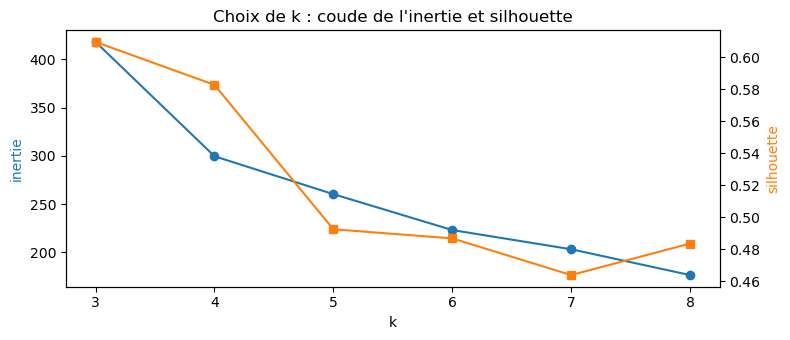

,inertie,silhouette,iterations,baisse_inertie_pct
k,,,,
3,418.002,0.609,14,NaN
4,299.613,0.583,8,28.323
5,260.366,0.493,23,13.099
6,223.196,0.487,15,14.276
7,203.306,0.464,17,8.911
8,176.547,0.484,18,13.162


In [15]:
choix_k = pd.DataFrame(resultats_k_cache).set_index("k")
mlflow.set_experiment(EXPERIENCE_CLUSTERING)
for k, ligne in choix_k.iterrows():
    with mlflow.start_run(run_name=f"kmeans_k{k}"):
        mlflow.log_params({"k": k, "features": "profil horaire moyen, jours ouvrés (24 valeurs)", "seed": SEED})
        mlflow.log_metrics({"inertie": ligne["inertie"], "silhouette": ligne["silhouette"],
                            "iterations": ligne["iterations"]})

fig, ax1 = plt.subplots(figsize=(8, 3.5))
ax1.plot(choix_k.index, choix_k["inertie"], marker="o", color="tab:blue")
ax1.set_xlabel("k")
ax1.set_ylabel("inertie", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(choix_k.index, choix_k["silhouette"], marker="s", color="tab:orange")
ax2.set_ylabel("silhouette", color="tab:orange")
ax1.set_title("Choix de k : coude de l'inertie et silhouette")
plt.tight_layout()
plt.show()
choix_k.assign(baisse_inertie_pct=(-choix_k["inertie"].pct_change() * 100)).round(3)

Le **coude** est net à **k = 4** : passer de 3 à 4 groupes fait baisser l'inertie de 28 %, les ajouts suivants de 9 à 14 % seulement. La silhouette est la plus haute à k = 3 (0,61), mais reste élevée à k = 4 (0,58) avant de chuter à k = 5 (0,49). On retient **k = 4**, qui sépare un groupe de plus pour une silhouette presque inchangée : on va voir que ce quatrième groupe a un sens clair.

         stations  pct_paris  taux_moyen  heure_min  heure_max  amplitude
cluster                                                                  
0             311       68.0        0.38         12          2       0.26
1             202       85.0        0.42          1         11       0.35
2             551       68.0        0.21         17          5       0.10
3             317       74.0        0.60          8         22       0.07


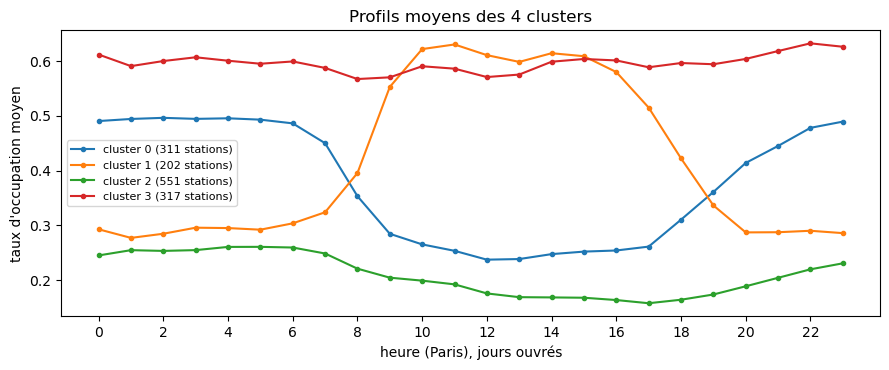

In [16]:
K_RETENU = 4
modele_kmeans = KMeans(k=K_RETENU, featuresCol="features", predictionCol="cluster", seed=SEED, maxIter=50).fit(profils)
stations_clusters = modele_kmeans.transform(profils)
centres = pd.DataFrame(modele_kmeans.clusterCenters(), columns=HEURES)

resume_clusters = (stations_clusters.groupBy("cluster")
                   .agg(F.count("*").alias("stations"),
                        F.round(F.avg(F.expr("int(arrondissement <= 20)")) * 100).alias("pct_paris"))
                   .orderBy("cluster").toPandas().set_index("cluster"))
resume_clusters["taux_moyen"] = centres.mean(axis=1).round(2)
resume_clusters["heure_min"] = centres.idxmin(axis=1)
resume_clusters["heure_max"] = centres.idxmax(axis=1)
resume_clusters["amplitude"] = (centres.max(axis=1) - centres.min(axis=1)).round(2)
print(resume_clusters)

fig, ax = plt.subplots(figsize=(9, 3.8))
for c in centres.index:
    ax.plot(HEURES, centres.loc[c], marker=".", label=f"cluster {c} ({resume_clusters.loc[c, 'stations']} stations)")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("heure (Paris), jours ouvrés")
ax.set_ylabel("taux d'occupation moyen")
ax.set_title(f"Profils moyens des {K_RETENU} clusters")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Quelques stations représentatives de chaque cluster (les plus proches de leur centre) :

In [17]:
centres_df = spark.createDataFrame([(i, [float(x) for x in c]) for i, c in enumerate(modele_kmeans.clusterCenters())],
                                   "cluster int, centre array<double>")
carres = F.zip_with(vector_to_array("features"), "centre", lambda a, b: (a - b) * (a - b))
distance = F.sqrt(F.aggregate(carres, F.lit(0.0), lambda somme, x: somme + x))
(stations_clusters.join(F.broadcast(centres_df), "cluster")
 .withColumn("distance", distance)
 .withColumn("rang", F.row_number().over(Window.partitionBy("cluster").orderBy("distance")))
 .filter("rang <= 4")
 .select("cluster", "station_id", "nom_station", "arrondissement", F.round("distance", 3).alias("distance"))
 .orderBy("cluster", "rang").show(4 * K_RETENU, truncate=False))

+-------+----------+-------------------------------------+--------------+--------+
|cluster|station_id|nom_station                          |arrondissement|distance|
+-------+----------+-------------------------------------+--------------+--------+
|0      |17023     |Porte d'Asnières                     |17            |0.079   |
|0      |17204     |Paul Bodin - Clichy                  |17            |0.095   |
|0      |21115     |Chancé Milly - Cimetière Communal Sud|21            |0.099   |
|0      |11007     |Jean Macé - Faidherbe                |11            |0.106   |
|1      |9013      |Mairie du 9ème                       |9             |0.137   |
|1      |13020     |Paul Klee - Place Augusta Holmes     |13            |0.143   |
|1      |22003     |Beffroy                              |22            |0.149   |
|1      |41606     |Pasteur - Gambetta                   |41            |0.169   |
|2      |23102     |Hôtel de Ville                       |23            |0.069   |
|2  

Les quatre clusters ont chacun une lecture claire, conforme aux deux familles de la question 3 du carnet 03 :

| Cluster | Stations | Profil | Lecture |
|---|---|---|---|
| 0 | 311 | pleines la nuit (0,49), vidées de 8 h à 17 h (0,24) | **résidentiel** : on part le matin, on rentre le soir |
| 1 | 202 | vides la nuit (0,29), pleines de 10 h à 16 h (0,62) | **lieux de travail** : on arrive le matin, on repart le soir ; 85 % dans Paris (Mairie du 9e, Paul Klee dans le 13e) |
| 2 | 551 | peu remplies toute la journée (0,16 à 0,26) | **stations souvent vides**, le plus grand groupe, un peu mieux garnies la nuit qu'en fin d'après-midi |
| 3 | 317 | pleines toute la journée (0,57 à 0,63) | **stations souvent pleines**, où il est difficile de rendre un vélo |

Les clusters 0 et 1 sont en **opposition de phase** : leurs courbes se croisent vers 8 h et 19 h, aux pointes. Ce sont les flux domicile-travail qui créent la tension du réseau. Les clusters 2 et 3 se distinguent par le **niveau** plutôt que par la forme : ce sont les stations à surveiller pour la régulation (pénurie de vélos d'un côté, de places de l'autre).

### Carte Folium

Chaque station est un point coloré par cluster ; la fenêtre surgissante donne son nom et son cluster. La
carte est aussi écrite en HTML dans `data/output/carte_clusters.html`. Les 1 400 lignes ramenées dans
Pandas servent uniquement à la visualisation.

In [18]:
COULEURS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f"]
points = stations_clusters.select("station_id", "nom_station", "arrondissement", "latitude", "longitude",
                                  "cluster").toPandas()

carte = folium.Map(location=[48.86, 2.35], zoom_start=12, tiles="cartodbpositron")
for _, s in points.iterrows():
    folium.CircleMarker(location=[s.latitude, s.longitude], radius=3, weight=0, fill=True, fill_opacity=0.85,
                        fill_color=COULEURS[s.cluster],
                        popup=f"{s.nom_station} ({s.arrondissement}) : cluster {s.cluster}").add_to(carte)
legende = "".join(f'<div><span style="color:{COULEURS[c]}">&#9679;</span> cluster {c} '
                  f"({resume_clusters.loc[c, 'stations']} stations)</div>" for c in resume_clusters.index)
carte.get_root().html.add_child(folium.Element(
    f'<div style="position:fixed;bottom:20px;left:20px;z-index:9999;background:white;padding:6px;'
    f'font-size:12px;border:1px solid grey">{legende}</div>'))
carte.save(str(SORTIES / "carte_clusters.html"))
carte

La même carte en image fixe, lisible là où le HTML de Folium ne s'affiche pas (sur GitHub, par exemple) :

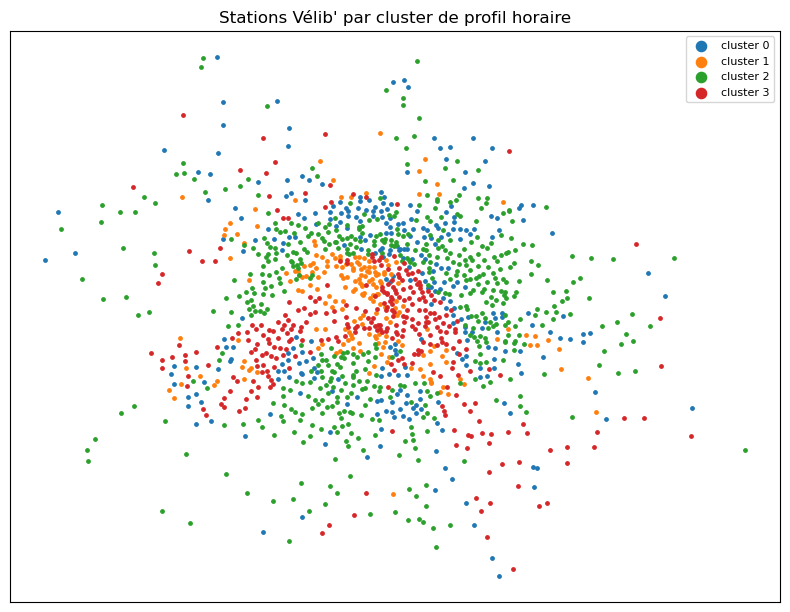

In [19]:
fig, ax = plt.subplots(figsize=(8, 6.5))
for c in resume_clusters.index:
    p = points[points["cluster"] == c]
    ax.scatter(p["longitude"], p["latitude"], s=6, color=COULEURS[c], label=f"cluster {c}")
ax.set_aspect(1 / 0.66)                      # cos(48,86°) : mètres égaux en latitude et longitude
ax.set_title("Stations Vélib' par cluster de profil horaire")
ax.legend(markerscale=3, fontsize=8)
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

Pour lire la carte avec des chiffres : la part de chaque cluster par zone (arrondissements de Paris
regroupés, et banlieue).

In [20]:
zone = (F.when(F.col("arrondissement").isin(1, 2, 3, 4, 8, 9), "centre et quartiers d'affaires (1-4, 8, 9)")
        .when(F.col("arrondissement").isin(5, 6, 7, 13, 14, 15), "rive gauche (5-7, 13-15)")
        .when(F.col("arrondissement").isin(16, 17), "ouest (16, 17)")
        .when(F.col("arrondissement").isin(10, 11, 12, 18, 19, 20), "est et nord (10-12, 18-20)")
        .otherwise("banlieue"))
(stations_clusters.withColumn("zone", zone)
 .groupBy("zone").pivot("cluster", list(range(K_RETENU))).count()
 .withColumn("stations", sum(F.col(str(c)) for c in range(K_RETENU)))
 .select("zone", "stations", *[F.round(F.col(str(c)) / F.col("stations") * 100).alias(f"cluster_{c}_pct")
                                for c in range(K_RETENU)])
 .orderBy("zone").show(truncate=False))

+------------------------------------------+--------+-------------+-------------+-------------+-------------+
|zone                                      |stations|cluster_0_pct|cluster_1_pct|cluster_2_pct|cluster_3_pct|
+------------------------------------------+--------+-------------+-------------+-------------+-------------+
|banlieue                                  |387     |26.0         |8.0          |45.0         |21.0         |
|centre et quartiers d'affaires (1-4, 8, 9)|191     |6.0          |45.0         |18.0         |31.0         |
|est et nord (10-12, 18-20)                |366     |32.0         |5.0          |47.0         |15.0         |
|ouest (16, 17)                            |123     |22.0         |7.0          |59.0         |11.0         |
|rive gauche (5-7, 13-15)                  |314     |18.0         |18.0         |30.0         |34.0         |
+------------------------------------------+--------+-------------+-------------+-------------+-------------+



La table par zone confirme et précise la carte :

- les **lieux de travail** (cluster 1, orange) sont au **centre** : 45 % des stations des 1er-4e, 8e et 9e arrondissements, 18 % sur la rive gauche, 8 % au plus ailleurs ;
- les stations **résidentielles** (cluster 0, bleu) sont surtout dans l'**est et le nord** (32 %, du 10e au 20e) et en banlieue (26 %), presque absentes du centre (6 %) ;
- les stations **souvent vides** (cluster 2, vert) dominent l'**ouest** (59 % dans les 16e et 17e), l'est et le nord (47 %) et la banlieue (45 %) ;
- les stations **souvent pleines** (cluster 3, rouge) sont sur la **rive gauche** (34 %) et au centre (31 %), là où les arrivées l'emportent sur les départs.

Le clustering n'a jamais vu les coordonnées : la cohérence géographique des groupes vient uniquement des profils d'occupation. Elle dessine la carte des déplacements domicile-travail : des quartiers résidentiels de l'est vers les bureaux du centre.

## 9. Mesures et bilan

In [21]:
enregistrer_mesures("05_mllib_prediction", {
    "lignes_jeu": n_jeu,
    "lignes_entrainement": n_entrainement,
    "lignes_test": n_test,
    "validation_croisee_s": round(duree_cv, 1),
    "entrainement_champion_s": round(duree_champion, 1),
    "meilleurs_parametres": MEILLEURS_PARAMETRES,
    "test": {nom: {k: round(v, 5) for k, v in m.items()} for nom, m in resultats.items()},
    "kmeans_sans_cache_s": round(duree_sans_cache, 1),
    "kmeans_avec_cache_s": round(duree_avec_cache, 1),
    "kmeans_remplissage_cache_s": round(duree_remplissage, 1),
    "kmeans_spark_ui": {"sans_cache": ui_sans_cache, "avec_cache": ui_avec_cache},
    "k_retenu": K_RETENU,
})
print(json.dumps(json.loads(MESURES_JSON.read_text(encoding="utf-8"))["05_mllib_prediction"], indent=2,
                 ensure_ascii=False))

{
  "lignes_jeu": 4083342,
  "lignes_entrainement": 3469961,
  "lignes_test": 612013,
  "validation_croisee_s": 153.4,
  "entrainement_champion_s": 53.1,
  "meilleurs_parametres": {
    "maxDepth": 7,
    "maxIter": 50
  },
  "test": {
    "persistance": {
      "rmse": 0.07999,
      "mae": 0.04654,
      "r2": 0.89214,
      "r2_variation": -0.0
    },
    "gbt": {
      "rmse": 0.07565,
      "mae": 0.04705,
      "r2": 0.90355,
      "r2_variation": 0.10571
    },
    "gbt_air": {
      "rmse": 0.07572,
      "mae": 0.04739,
      "r2": 0.90335,
      "r2_variation": 0.10392
    },
    "gbt_meme_test": {
      "rmse": 0.07565,
      "mae": 0.04705,
      "r2": 0.90355,
      "r2_variation": 0.10571
    },
    "fm": {
      "rmse": 0.08309,
      "mae": 0.05491,
      "r2": 0.88363,
      "r2_variation": -0.07896
    }
  },
  "kmeans_sans_cache_s": 41.3,
  "kmeans_avec_cache_s": 2.5,
  "kmeans_remplissage_cache_s": 1.5,
  "kmeans_spark_ui": {
    "sans_cache": {
      "jobs": 335,
 

## Bilan du Jour 3 matin

| Élément | Résultat |
|---|---|
| Jeu de features | 4,08 millions d'heures-stations ; `t-1` et `t-4` vérifiés en temps (un `LAG` naïf se serait trompé sur 5,7 % des lignes) |
| Découpage | temporel : 85 % / 15 %, marge d'une heure ; coupure le 21/03/2021 à 18 h UTC |
| Validation croisée | 3 plis **temporels**, 6 combinaisons ; meilleure : profondeur 7, 50 arbres |
| Champion (test) | RMSE 0,0756 contre 0,0800 pour la persistance ; R² 0,904 ; 10,6 % de la variation horaire expliquée ; jusqu'à -16 % d'erreur à 8 h |
| MLflow | runs `persistance`, `validation_croisee` (6 runs enfants), `gbt_champion`, `gbt_qualite_air`, `fm_regressor`, et 6 runs K-Means ; modèle enregistré, alias `champion` |
| Sauvegarde | `save()` / `PipelineModel.load()` et `models:/...@champion` : prédictions identiques sur le 9 avril |
| Bonus | NO2 / PM2.5 : aucun gain ; `FMRegressor` : moins bon que la persistance |
| K-Means | k = 4 (coude) : résidentiel, lieux de travail, souvent vides, souvent pleines |
| Cache (contrainte n°6, calcul itératif) | boucle k = 3..8 : 41 s sans cache, 2,5 s avec (16 fois plus vite) ; 1,5 Go relus contre 56 Mo |

La prédiction à une heure reste dominée par l'état présent de la station : le modèle apporte surtout aux pointes, quand les stations changent vite. Pour aller plus loin, il faudrait des features propres à la station (son cluster, son profil moyen à l'heure cible) et un horizon plus long, où la persistance perd son avantage.

On libère le cache et la session.

In [22]:
profils.unpersist()
spark.stop()
print("SparkSession arrêtée.")

SparkSession arrêtée.
